# Holding a survey out: what the calibrated model predicts for a plant it has not seen

**Question:** When the calibrated capacity model is refitted without one survey, how well does it predict that survey's throughput, and how much better is that than guessing the mean of the others?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 05-real-surveys
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- explain what a leave-one-survey-out fold is, and say which rows it fits and which it predicts;
- refit the calibrated capacity model on nine surveys and read its held-out prediction for the tenth;
- compare the ten held-out predictions with the constant-mean baseline that a model with no skill would give;
- say why the leaky variant of the fold exists, and where its full comparison is made.

## Setup

Numpy and matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The imports are the survey reader, the engine with its calibrated lane and the CrusherCal module of the pipeline, whose public functions fit and predict fold by fold.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Public pipeline functions only: the notebook defines no method of its own
from pipeline.hp500.surveys import read_surveys
from pipeline.model.crusher import evaluate, operating_from_survey
from pipeline.model.crusher.capacity import HP500_QREF
from pipeline.hp500 import loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The ten HP500 surveys. Owner: Rocha, Campos, Silva and Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Licence class: CC BY 4.0 (open access, attribution), see `conventions/third-party-datasets.md`; the ten survey rows are transcribed from Table A1 of the paper. File read: `data/examples/hp500-surveys.csv`. The engine's results at the surveys are computed in the notebook, and nothing committed is read back.

The cell reads the table and keeps the measured throughput and the two regressors of the free-form model, the setting and the feed f80.

In [2]:
# Read the survey table and keep the measured throughput and the regressors, the setting and the f80
surveys = read_surveys().accepted
measured = np.array([s.feed_tph for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
print("surveys:", len(surveys), "| measured throughput [t/h]:", measured)

surveys: 10 | measured throughput [t/h]: [1639. 1267. 1240. 1034. 1124.  813. 1050. 1138.  820. 1334.]


## Method

**Step 1, the fold.** A model that is fitted to ten surveys and judged on the same ten tells how well it describes them, not how it would do on an eleventh. The leave-one-survey-out protocol answers the second question: for each survey $i$, fit on the other nine and predict $i$, then judge the ten predictions together. The model's only free number for the throughput is the capacity base $Q_T$, which each fold refits to its nine surveys by least squares (Rocha et al., 2024; https://doi.org/10.3390/min14090919). CrusherCal builds the folds with `loo.fold_indices`, and the cell prints the training rows of survey 3 in the strict fold and in the leaky variant, which keeps the survey in its own training set and exists to measure how much that flatters a model.

In [3]:
# Training rows for survey 3 (index 2) in the strict fold and in the leaky variant
print("strict fold, rows fitted:", loo.fold_indices(10, 2, leaky=False).tolist())
print("leaky variant, rows fitted:", loo.fold_indices(10, 2, leaky=True).tolist())

strict fold, rows fitted: [0, 1, 3, 4, 5, 6, 7, 8, 9]
leaky variant, rows fitted: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


The two predictions for survey 3 are made with CrusherCal's public functions, which `loo.build` calls fold by fold. The capacity model M0 predicts the capacity base fitted to the training rows (`fit_capacity_base`) times the survey's capacity factor (`predict_capacity`), where the factor is the engine's throughput over the paper's base of 647 t/h. The free-form regression M2 (`fit_freeform`, `predict_freeform`) fits a plane in the setting and the f80 with no physics. The cell asks for both in the strict fold and in the leaky one, next to the measurement, and prints M2's three coefficients.

In [4]:
# Predict survey 3 with the capacity model (M0) and the free-form regression (M2), strict and leaky
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
shape = np.array([r.throughput_tph for r in runs]) / HP500_QREF
for name, leaky in (("strict", False), ("leaky", True)):
    rows = loo.fold_indices(10, 2, leaky=leaky)
    qt = loo.fit_capacity_base(shape, measured, rows)
    coef = loo.fit_freeform(features, measured, rows)
    m0 = loo.predict_capacity(qt, shape, 2)
    m2 = loo.predict_freeform(coef, features[2])
    print(f"{name:7s} QT {qt:6.1f}  M0 {m0:7.1f} t/h  M2 {m2:7.1f} t/h  measured {measured[2]:.0f} t/h")
    print("        M2 coefficients (intercept, setting, f80):", np.round(coef, 2))

strict  QT  681.5  M0  1165.8 t/h  M2   981.0 t/h  measured 1240 t/h
        M2 coefficients (intercept, setting, f80): [-1100.32    38.94     4.51]
leaky   QT  686.0  M0  1173.4 t/h  M2  1078.3 t/h  measured 1240 t/h
        M2 coefficients (intercept, setting, f80): [-802.3    36.56    2.68]


The leaky fold, which has seen survey 3, lands nearer to the measurement than the strict one for both models, and the free-form regression gains the most from the leak, as it has the most coefficients to bend towards the point it saw: its three coefficients move visibly between the two folds, while the capacity model moves only its one base. The capacity base is the one number each fold refits, and the next cell prints it for the ten strict folds.

In [5]:
# The capacity base refitted by each of the ten strict folds
folds = [loo.fold_indices(10, i, leaky=False) for i in range(10)]
bases = [loo.fit_capacity_base(shape, measured, rows) for rows in folds]
print("refitted capacity base per fold [t/h]:", np.round(bases, 1))
print("range:", round(min(bases), 1), "to", round(max(bases), 1), "| the paper's value:", HP500_QREF)

refitted capacity base per fold [t/h]: [659.3 687.1 681.5 695.3 689.3 698.3 682.9 683.7 697.9 683.4]
range: 659.3 to 698.3 | the paper's value: 647


The base moves between 659 and 698 t/h from fold to fold, a spread of about 6 percent produced by removing one survey out of ten, and every fold sits above the paper's 647 t/h: that is how much a one-parameter fit moves on ten points, and the uncertainty that a single in-sample value of it carries and that the held-out protocol makes visible.

**Step 2, the held-out predictions.** With the ten folds, the held-out prediction of survey $i$ is the capacity factor of $i$ times the base that its fold fitted. The cell lists the prediction for each survey beside the measurement, the residual (the measured minus the predicted), the error as a percentage of the measurement, and the mean absolute percentage error from `loo.mape`. A survey with a large residual is one that the nine others did not prepare the model for.

In [6]:
# Held-out prediction of the capacity model for each survey, beside the measurement, and its MAPE
held_out = np.array([loo.predict_capacity(qt, shape, i) for i, qt in enumerate(bases)])
print("survey  measured  held-out   residual    error")
for s, m, p in zip(surveys, measured, held_out):
    print(f"{s.survey:6d} {m:9.0f} {p:9.1f} {m - p:+9.1f} {(p - m) / m * 100:+7.1f} %")
print("held-out MAPE of the capacity model:", round(loo.mape(measured, held_out), 2), "%")

survey  measured  held-out   residual    error
     1      1639    1231.9    +407.1   -24.8 %
     2      1267    1283.8     -16.8    +1.3 %
     3      1240    1165.8     +74.2    -6.0 %
     4      1034    1189.4    -155.4   +15.0 %
     5      1124    1179.1     -55.1    +4.9 %
     6       813    1047.5    -234.5   +28.8 %
     7      1050     988.4     +61.6    -5.9 %
     8      1138    1097.5     +40.5    -3.6 %
     9       820    1046.9    -226.9   +27.7 %
    10      1334    1294.9     +39.1    -2.9 %
held-out MAPE of the capacity model: 12.09 %


The residuals are of both signs and of very different sizes: survey 1 is the extreme, 407 t/h above what the other nine predict, and surveys 6 and 9, at 40 mm and 813 and 820 t/h, are about 230 t/h below. The figure puts the held-out predictions on a parity plot against the measurements, with the 29 percent band that the expectation gate of notebook 02 of topic 05 used.

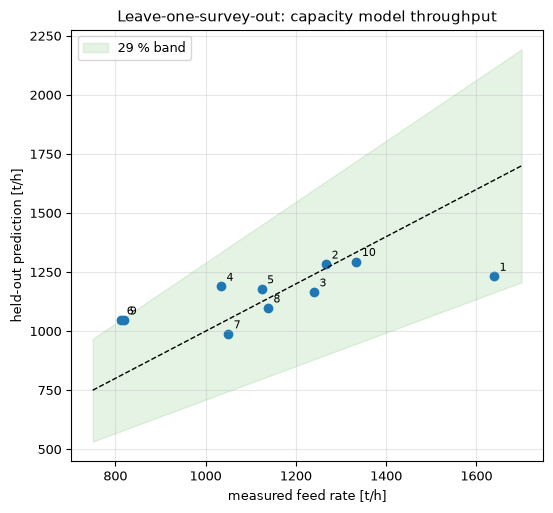

In [7]:
# Parity plot of the held-out predictions against the measured throughput, with the 29 % band
fig, ax = plt.subplots(figsize=(5.6, 5.2))
line = np.array([750, 1700])
ax.fill_between(line, line * 0.71, line * 1.29, color="tab:green", alpha=0.12, label="29 % band")
ax.plot(line, line, "k--", lw=1)
ax.scatter(measured, held_out)
for s, m, p in zip(surveys, measured, held_out):
    ax.annotate(str(s.survey), (m, p), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("measured feed rate [t/h]")
ax.set_ylabel("held-out prediction [t/h]")
ax.set_title("Leave-one-survey-out: capacity model throughput")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

All ten points fall inside the green band, and three of them near its edge: survey 1 is 24.8 percent below its measurement (1232 against 1639 t/h), and surveys 6 and 9 are 28.8 and 27.7 percent above theirs, as the error column printed. The predictions occupy a narrow range, 988 to 1295 t/h, much narrower than the measurements, because the model only knows the setting. What the figure cannot say is whether this is good: a model that predicted the same number every time would also land inside a wide band. The comparison with that model is the next step.

**Step 3, the baseline.** A model with no skill predicts, for the held-out survey, the mean of the other nine: the constant-mean baseline. A model that is worth anything must beat it, held out. The cell builds the baseline fold by fold, holds out the free-form regression M2 in the same ten folds, and prints the mean absolute percentage error of the three with `loo.mape`, and the surveys on which the capacity model beats the baseline. The figure draws each survey's absolute error for the capacity model and for the baseline.

In [8]:
# The constant-mean baseline and the free-form regression, both held out, beside the capacity model
baseline = np.array([measured[rows].mean() for rows in folds])
free_form = np.array([loo.predict_freeform(loo.fit_freeform(features, measured, rows), features[i])
                      for i, rows in enumerate(folds)])
models = (("capacity model M0", held_out), ("free-form M2", free_form), ("mean of the other nine", baseline))
for name, pred in models:
    print(f"{name:24s} held-out MAPE {loo.mape(measured, pred):6.2f} %")
better = np.abs(held_out - measured) < np.abs(baseline - measured)
print("surveys where the capacity model beats the baseline:", int(better.sum()), "of 10:", np.flatnonzero(better) + 1)
print("baseline prediction for surveys 4, 5 and 8 [t/h]:", baseline[[3, 4, 7]].round(0))

capacity model M0        held-out MAPE  12.09 %
free-form M2             held-out MAPE  12.18 %
mean of the other nine   held-out MAPE  18.29 %
surveys where the capacity model beats the baseline: 7 of 10: [ 1  2  3  6  7  9 10]
baseline prediction for surveys 4, 5 and 8 [t/h]: [1158. 1148. 1147.]


The figure compares the two absolute errors survey by survey, in percent of the measurement.

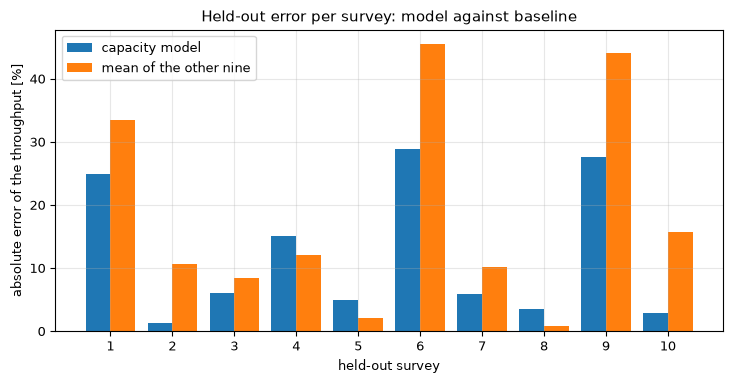

In [9]:
# Absolute held-out error of the capacity model and of the baseline, per survey
x = np.arange(1, 11)
fig, ax = plt.subplots()
ax.bar(x - 0.2, np.abs(held_out - measured) / measured * 100, 0.4, label="capacity model")
ax.bar(x + 0.2, np.abs(baseline - measured) / measured * 100, 0.4, label="mean of the other nine")
ax.set_xticks(x)
ax.set_xlabel("held-out survey")
ax.set_ylabel("absolute error of the throughput [%]")
ax.set_title("Held-out error per survey: model against baseline")
ax.legend()
fig.tight_layout()
plt.show()

The capacity model beats the baseline on 7 of the 10 surveys (1, 2, 3, 6, 7, 9 and 10) and loses on 4, 5 and 8: the bars show the baseline winning on exactly the surveys whose throughput (1034, 1124 and 1138 t/h) sits near the mean of the other nine, which the last line printed, and the model winning clearly on the extremes it can follow through the setting. In the totals the model is at 12.09 percent against 18.29 percent for the baseline, and the free-form regression, with its three fitted coefficients, is at 12.18 percent: held out, it is not better than the physics. The figure shows the ordering; it does not show how stable it is with ten points, which is what notebook 02 examines, and the comparison of these held-out numbers with the in-sample numbers of the same models is made once, in notebook 03.

## Results

**Answer:** held out, the calibrated capacity model predicts the throughput of a survey with a mean absolute error of 12.09 percent, against 18.29 percent for the mean of the other nine, and 12.18 percent for an unconstrained regression on the setting and the f80. All ten held-out predictions are within 29 percent of the measurement, and the three largest errors are surveys 1, 6 and 9 (24.8, 28.8 and 27.7 percent); survey 1 is 407 t/h above its prediction. The refitted capacity base moves between 659.3 and 698.3 t/h across the ten folds.

The parity figure shows a narrow band of predictions against a wide band of measurements, and the bar chart the survey-by-survey comparison with the baseline. A validator would conclude that the capacity model has skill that survives the hold-out, and that adding free parameters bought nothing out of sample. The honest limits: ten surveys of one machine make each number coarse, and the held-out protocol can say how the model does on a new survey of this crusher and this ore, not on another machine.

## Summary

A leave-one-survey-out fold refits the capacity base on nine surveys and predicts the tenth. On throughput the calibrated model beats the mean baseline held out by 6 points and is as good as an unconstrained regression. Notebook 02 asks how much to trust that on ten points, with both targets, the residual model and the label-shuffle control; notebook 03 runs the paper's in-sample protocol against this one.

## References

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919